# FIGNN Validation

This notebook evaluates the existing 29-subject LOSO outputs.

## Primary question

Does the learned representation produce an emergent workload trajectory

\[
C_0 ightarrow C_1 ightarrow C_2
\]

where the 1-back representation lies between the 0-back and 2-back representations?

### Primary criterion

`oneback_between_x`

This is stronger than the supporting criterion:

\[
d(C_0,C_1) < d(C_0,C_2)
\]

The notebook also evaluates:

- subject-level exact confidence intervals and binomial tests;
- the three subjects that satisfy the weaker distance criterion but fail the stronger trajectory criterion;
- Stage-2 calibration baselines, when their output files are available;
- frozen-model PLV-threshold sensitivity, when threshold outputs are available;
- ablation results after the training/evaluation pipeline finishes.

Procrustes is retained only as a supplementary descriptive metric.


In [16]:
from pathlib import Path
import copy, glob, json, os, pickle, re, sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from scipy.stats import binomtest
from statsmodels.stats.proportion import proportion_confint
from sklearn.linear_model import LinearRegression

import torch
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_mean_pool

PROJECT_ROOT = Path("/home/nvidia/24BCE1793/fignn_cni__project" )
OUTPUT_ROOT = Path("/lp-dev/24BCE1793/outputs" )
DATA_ROOT = Path("/lp-dev/24BCE1793/data" )
BASE_DIR = OUTPUT_ROOT /"evaluation_loso_all29"

FIG_DIR = (BASE_DIR /"validation_figures" )
FIG_DIR.mkdir(parents=True,exist_ok=True )

REPORT_PATH = (BASE_DIR /"loso_all29_report.json" )
SUBJECT_CSV = (BASE_DIR /"loso_all29_subject_metrics.csv" )
STAGE2_DIR = ( OUTPUT_ROOT / "stage2_calibration" )
THRESHOLD_DIR = ( OUTPUT_ROOT / "plv_threshold_sensitivity" )

ABLATION_DIR = ( OUTPUT_ROOT / "ablation_logs" )
GRAPHS_PATH = DATA_ROOT / "processed" / "all_graphs_29sub.pkl"
LOSO_ROOT = OUTPUT_ROOT / "loso"
OUTPUT_DIR = OUTPUT_ROOT / "stage2_calibration"
OUTPUT_PATH = OUTPUT_DIR / "stage2_baseline_results.csv"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_CSV=ABLATION_DIR/"ablation_detailed_results.csv"
SUMMARY_CSV=ABLATION_DIR/"ablation_summary.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
TEST_SUBJECTS = [7, 15, 22, 29]
VARIANTS = ["full", "no_plv", "no_band_weight", "node_feature_mlp", "gcn", "no_supcon", "band_power"]


sys.path.insert( 0, str(PROJECT_ROOT) )

from src.models.model import FIGNNEncoder
from ablation_train import ( NodeFeatureMLPEncoder, GCNEncoder, EmbeddingClassifier, BandPowerClassifier, make_encoder, )
from plv_threshold_sensitivity import ( THRESHOLDS, OUTPUT_DIR as THRESHOLD_OUTPUT_DIR, load_pre_graph_records, make_threshold_graphs, evaluate_threshold, )
with open(REPORT_PATH, "r") as f:
    report = json.load(f)

df = pd.read_csv(SUBJECT_CSV)
assert len(df) == 29
assert df["subject"].nunique() == 29
n = len(df)
d01_lt_d02 = ( df["d01_x"] < df["d02_x"] )
between_x = ( df["oneback_between_x"] .astype(bool) )
between_y = ( df["oneback_between_y"] .astype(bool) )
print(f"Loaded {n} LOSO subjects.")

Loaded 29 LOSO subjects.


## 1. Primary trajectory result

The weaker condition only checks whether 1-back is closer to 0-back than 2-back is.

The stronger condition checks whether the projected 1-back position lies within the 0-back to 2-back segment and satisfies the perpendicular-distance rule used by the evaluation pipeline.

Therefore, the stronger `oneback_between_x` criterion is the primary result.


In [3]:
def exact_ci(k, n):
    low, high = proportion_confint(k, n, alpha=0.05, method="beta")
    return 100 * low, 100 * high

primary_rows = []

for label, mask in [("Weak: d01 < d02", d01_lt_d02),("Primary: 1-back between, X", between_x),("Secondary: 1-back between, Y", between_y), ]:
    k = int(mask.sum())
    low, high = exact_ci(k, n)

    primary_rows.append({"criterion": label,"successes": k,"total": n,"proportion_%": 100 * k / n,"95% CI": f"{low:.1f}%–{high:.1f}%","one-sided_binomial_p_vs_0.5": binomtest(k, n, p=0.5, alternative="greater").pvalue,})

primary_results = pd.DataFrame(primary_rows)
display(primary_results.round(4))


,criterion,successes,total,proportion_%,95% CI,one-sided_binomial_p_vs_0.5
0,Weak: d01 < d02,28,29,96.5517,82.2%–99.9%,0.0000
1,"Primary: 1-back between, X",25,29,86.2069,68.3%–96.1%,0.0001
2,"Secondary: 1-back between, Y",25,29,86.2069,68.3%–96.1%,0.0001


In [15]:
# Identify the subjects that satisfy the weak condition but fail the stronger between-segment criterion.

weak_only = df.loc[ d01_lt_d02 & ~between_x, [ "subject", "d01_x", "d02_x", "d12_x", "relative_1back_position", "perpendicular_distance", "angle_deg", "path_efficiency", "oneback_between_x", "oneback_between_y", ] ].sort_values("subject")

print( f"{len(weak_only)} subjects satisfy d01 < d02 " "but fail the stronger between-segment criterion." )

display(weak_only)


3 subjects satisfy d01 < d02 but fail the stronger between-segment criterion.


,subject,d01_x,d02_x,d12_x,relative_1back_position,perpendicular_distance,angle_deg,path_efficiency,oneback_between_x,oneback_between_y
1,2,0.027437,0.080379,0.091393,-0.088151,0.026506,121.825569,0.676426,False,False
10,11,0.024200,0.035203,0.043984,-0.044250,0.024150,126.993729,0.516292,False,False
11,12,0.008166,0.025151,0.030825,-0.198330,0.006466,139.758499,0.645048,False,False


### Interpretation of the three weak-only subjects

These subjects are not automatically errors.

They demonstrate why `d01 < d02` is insufficient by itself:

- `d01 < d02` means only that 1-back is closer to 0-back than 2-back is.
- It does not guarantee that 1-back lies on the 0-back → 2-back trajectory.
- A subject can satisfy the distance inequality while having a projection position outside `[0, 1]`, or while deviating too far from the endpoint line.


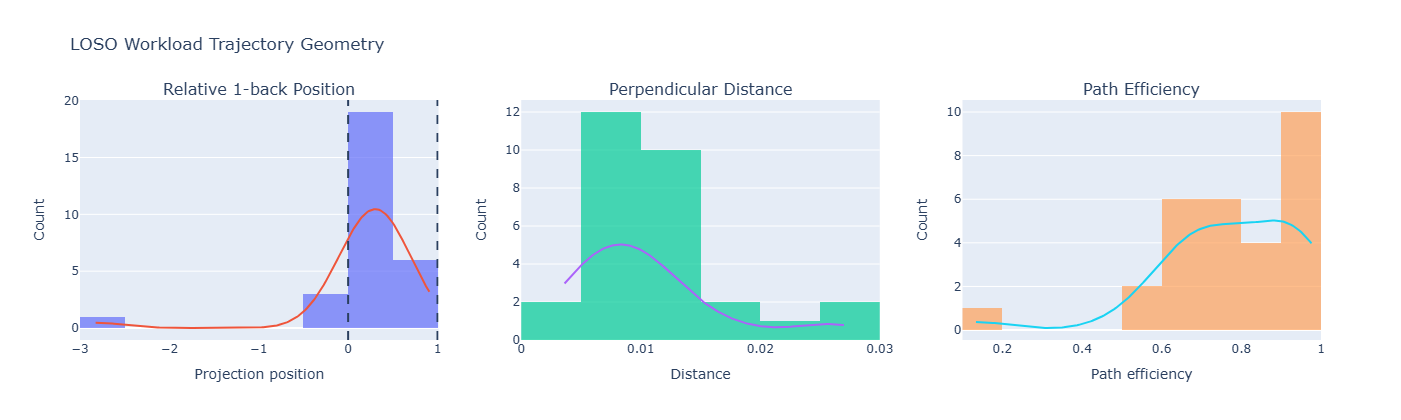

In [10]:
from scipy.stats import gaussian_kde

fig = make_subplots(rows=1,cols=3,subplot_titles=["Relative 1-back Position","Perpendicular Distance","Path Efficiency"])

for col,key in enumerate(["relative_1back_position","perpendicular_distance","path_efficiency"],1):
    x=df[key].dropna().values
    fig.add_trace(go.Histogram(x=x,nbinsx=10,opacity=0.7,showlegend=False),row=1,col=col)
    kde=gaussian_kde(x)
    xx=np.linspace(x.min(),x.max(),200)
    fig.add_trace(go.Scatter(x=xx,y=kde(xx)*len(x)*(x.max()-x.min())/10,mode="lines",showlegend=False),row=1,col=col)

fig.add_vline(x=0,line_dash="dash",row=1,col=1)
fig.add_vline(x=1,line_dash="dash",row=1,col=1)

fig.update_xaxes(title="Projection position",row=1,col=1)
fig.update_xaxes(title="Distance",row=1,col=2)
fig.update_xaxes(title="Path efficiency",row=1,col=3)
fig.update_yaxes(title="Count",row=1,col=1)
fig.update_yaxes(title="Count",row=1,col=2)
fig.update_yaxes(title="Count",row=1,col=3)

fig.update_layout(title="LOSO Workload Trajectory Geometry",height=420)
fig.show()
fig.write_html(FIG_DIR/"primary_geometry.html")

## 2. Stage-2 calibration baselines

This section expects the Stage-2 pipeline to export one row per subject and method.

Required methods:

- `population_only`
- `midpoint`
- `regression`
- `geometric_calibration`

The comparison must use the same held-out subjects and the same evaluation metrics for every method.

**Important:** this notebook cannot recreate Stage-2 calibration from the final summary CSV alone. The calibration pipeline must first export the per-subject baseline results.


In [9]:
# ============================================================
# STAGE 2 — LOSO CALIBRATION BASELINE COMPARISON
# Methods: population_only, midpoint, regression, frozen_geometric
# Evaluation: 64-D Euclidean error against the unseen subject's true 1B centroid.
# ============================================================

print("Loading graphs...")
with open(GRAPHS_PATH, "rb") as f:
    all_graphs = pickle.load(f)
print(f"Loaded {len(all_graphs)} graphs")

checkpoint_files = glob.glob(os.path.join(LOSO_ROOT, "**", "fignn_final.pth"), recursive=True)
if not checkpoint_files:
    raise FileNotFoundError(f"No LOSO checkpoints found under:\n{LOSO_ROOT}")

subject_checkpoints = {}
for path in checkpoint_files:
    match = re.search(r"subject[_-]?(\d+)", path, re.IGNORECASE)
    if match:
        subject_checkpoints[int(match.group(1))] = path

print(f"Found {len(subject_checkpoints)} LOSO checkpoints")
if len(subject_checkpoints) == 0:
    raise RuntimeError("No subject-specific LOSO checkpoints were detected.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def compute_train_stats(graphs):
    """Compute normalization statistics using only the 28 LOSO training subjects."""
    all_x = torch.cat([g.x for g in graphs], dim=0)
    mean = all_x.mean(dim=0)
    std = all_x.std(dim=0).clamp(min=1e-8)
    return mean, std

@torch.no_grad()
def get_embeddings(model, graphs, mean, std, device, batch_size=128):
    """Generate frozen 64-D embeddings."""
    processed_graphs = []
    for graph in graphs:
        graph_copy = copy.copy(graph)
        graph_copy.x = (graph.x.clone() - mean) / std
        processed_graphs.append(graph_copy)

    loader = DataLoader(processed_graphs, batch_size=batch_size, shuffle=False)
    model.eval()
    all_z, all_y = [], []

    for batch in loader:
        batch = batch.to(device)
        z = model(batch)
        all_z.append(z.detach().cpu().numpy())
        all_y.append(batch.y.view(-1).cpu().numpy())

    return np.vstack(all_z), np.concatenate(all_y)

def get_condition_centroids(z, y):
    """Labels: 3 -> REST, 0 -> 0-back, 1 -> 1-back, 2 -> 2-back."""
    centroids = {}
    condition_labels = [(3, "REST"), (0, "0B"), (1, "1B"), (2, "2B")]

    for label, name in condition_labels:
        condition_z = z[y == label]
        if len(condition_z) == 0:
            raise ValueError(f"No samples found for condition {name}")
        centroids[name] = condition_z.mean(axis=0)

    return centroids

def projection_position(rest, target, two_back):
    """Project target onto the REST -> 2-back vector; alpha=0 is REST, alpha=1 is 2-back."""
    direction = two_back - rest
    numerator = np.dot(target - rest, direction)
    denominator = np.dot(direction, direction)
    if denominator < 1e-12:
        return np.nan
    return numerator / denominator

def population_only_prediction(train_centroids):
    """Predict unseen 1-back using only the population 1-back centroid from the 28 training subjects."""
    return np.mean([c["1B"] for c in train_centroids], axis=0)

def midpoint_prediction(true_rest, true_two_back):
    """Fixed midpoint baseline using alpha=0.5."""
    return true_rest + 0.5 * (true_two_back - true_rest)

def regression_prediction(train_centroids, true_rest, true_two_back):
    """Fit [REST_64D, 2B_64D] -> 1B_64D on the 28 training subjects."""
    x_train = np.asarray([np.concatenate([c["REST"], c["2B"]]) for c in train_centroids], dtype=np.float32)
    y_train = np.asarray([c["1B"] for c in train_centroids], dtype=np.float32)
    x_test = np.concatenate([true_rest, true_two_back]).reshape(1, -1)

    if len(x_train) < 2:
        return population_only_prediction(train_centroids)

    regression_model = LinearRegression()
    regression_model.fit(x_train, y_train)
    return regression_model.predict(x_test)[0]

def frozen_geometric_prediction(train_centroids, true_rest, true_two_back):
    """Learn alpha from the 28 training subjects and apply it to the unseen subject's REST -> 2-back vector."""
    alpha_values = []
    for c in train_centroids:
        alpha = projection_position(c["REST"], c["1B"], c["2B"])
        if np.isfinite(alpha):
            alpha_values.append(alpha)

    if len(alpha_values) == 0:
        raise ValueError("Could not calculate population alpha.")

    alpha_population = float(np.mean(alpha_values))
    return true_rest + alpha_population * (true_two_back - true_rest)

# ============================================================
# MAIN LOSO CALIBRATION EXPERIMENT
# ============================================================

results = []

for test_subject in sorted(subject_checkpoints):
    print()
    print("=" * 70)
    print(f"Processing unseen Subject {test_subject}")
    print("=" * 70)

    train_graphs = [g for g in all_graphs if g.subject != test_subject]
    test_graphs = [g for g in all_graphs if g.subject == test_subject]
    train_subjects = sorted(set(g.subject for g in train_graphs))

    if len(train_subjects) != 28:
        raise ValueError(f"Expected 28 training subjects, got {len(train_subjects)} for test subject {test_subject}")

    mean, std = compute_train_stats(train_graphs)

    checkpoint_path = subject_checkpoints[test_subject]
    model = FIGNNEncoder().to(device)
    state_dict = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(state_dict)
    model.eval()

    train_subject_centroids = []
    for subject in train_subjects:
        subject_graphs = [g for g in train_graphs if g.subject == subject]
        subject_z, subject_y = get_embeddings(model=model, graphs=subject_graphs, mean=mean, std=std, device=device)
        train_subject_centroids.append(get_condition_centroids(subject_z, subject_y))

    test_z, test_y = get_embeddings(model=model, graphs=test_graphs, mean=mean, std=std, device=device)
    test_centroids = get_condition_centroids(test_z, test_y)
    true_rest = test_centroids["REST"]
    true_1B = test_centroids["1B"]
    true_two_back = test_centroids["2B"]

    predictions = {
        "population_only": population_only_prediction(train_centroids=train_subject_centroids),
        "midpoint": midpoint_prediction(true_rest=true_rest, true_two_back=true_two_back),
        "regression": regression_prediction(train_centroids=train_subject_centroids, true_rest=true_rest, true_two_back=true_two_back),
        "frozen_geometric": frozen_geometric_prediction(train_centroids=train_subject_centroids, true_rest=true_rest, true_two_back=true_two_back),
    }

    for method, prediction in predictions.items():
        prediction = np.asarray(prediction, dtype=np.float64)
        error_64d = float(np.linalg.norm(prediction - true_1B))

        result_row = {
            "subject": test_subject,
            "method": method,
            "error_64D": error_64d,
            "prediction_norm": float(np.linalg.norm(prediction)),
            "true_1B_norm": float(np.linalg.norm(true_1B)),
            "rest_norm": float(np.linalg.norm(true_rest)),
            "two_back_norm": float(np.linalg.norm(true_two_back)),
        }

        if method in {"midpoint", "frozen_geometric"}:
            alpha = projection_position(true_rest, prediction, true_two_back)
            result_row["prediction_alpha"] = float(alpha) if np.isfinite(alpha) else np.nan
        else:
            result_row["prediction_alpha"] = np.nan

        results.append(result_row)
        print(f"{method:20s} | 64-D error: {error_64d:.6f}")

# ============================================================
# SAVE AND LOAD RESULTS
# ============================================================

stage2 = pd.DataFrame(results).sort_values(by=["subject", "method"]).reset_index(drop=True)
required_columns = {"subject", "method", "error_64D", "prediction_norm", "true_1B_norm", "rest_norm", "two_back_norm", "prediction_alpha"}
missing = required_columns - set(stage2.columns)

if missing:
    raise ValueError(f"Stage-2 result is missing columns: {missing}")

stage2.to_csv(OUTPUT_PATH, index=False)
stage2 = pd.read_csv(OUTPUT_PATH)

print()
print("=" * 70)
print("STAGE 2 CALIBRATION RESULTS")
print("=" * 70)
print(f"Saved to: {OUTPUT_PATH}")
print(f"Subjects: {stage2['subject'].nunique()}")
print(f"Methods: {stage2['method'].nunique()}")
print(f"Rows: {len(stage2)}")
display(stage2)

# ============================================================
# METHOD SUMMARY
# ============================================================

summary = stage2.groupby("method")["error_64D"].agg(mean="mean", std="std", median="median", count="count").sort_values("mean").round(6)

print()
print("=" * 70)
print("METHOD-WISE 64-D ERROR SUMMARY")
print("=" * 70)
display(summary)

# ============================================================
# OPTIONAL PAIRED COMPARISON AGAINST POPULATION BASELINE
# ============================================================

baseline_errors = stage2[stage2["method"] == "population_only"][["subject", "error_64D"]].rename(columns={"error_64D": "population_error_64D"})
comparison = stage2.merge(baseline_errors, on="subject", how="left")
comparison["absolute_improvement"] = comparison["population_error_64D"] - comparison["error_64D"]
comparison["percent_improvement"] = np.where(comparison["population_error_64D"] > 1e-12, 100 * comparison["absolute_improvement"] / comparison["population_error_64D"], np.nan)
comparison["improved_over_population"] = comparison["error_64D"] < comparison["population_error_64D"]

print()
print("=" * 70)
print("COMPARISON AGAINST POPULATION-ONLY BASELINE")
print("=" * 70)

display(comparison[["subject", "method", "error_64D", "population_error_64D", "absolute_improvement", "percent_improvement", "improved_over_population"]].sort_values(by=["subject", "method"]).round(6))


Loading graphs...
Loaded 27666 graphs
Found 29 LOSO checkpoints
Using device: cuda

Processing unseen Subject 1
population_only      | 64-D error: 0.055406
midpoint             | 64-D error: 0.077618
regression           | 64-D error: 0.122509
frozen_geometric     | 64-D error: 0.053604

Processing unseen Subject 2
population_only      | 64-D error: 0.115786
midpoint             | 64-D error: 0.050664
regression           | 64-D error: 0.111786
frozen_geometric     | 64-D error: 0.049041

Processing unseen Subject 3
population_only      | 64-D error: 0.182831
midpoint             | 64-D error: 0.065032
regression           | 64-D error: 0.162575
frozen_geometric     | 64-D error: 0.045912

Processing unseen Subject 4
population_only      | 64-D error: 0.031782
midpoint             | 64-D error: 0.060210
regression           | 64-D error: 0.054354
frozen_geometric     | 64-D error: 0.037547

Processing unseen Subject 5
population_only      | 64-D error: 0.053188
midpoint             | 6

,subject,method,error_64D,prediction_norm,true_1B_norm,rest_norm,two_back_norm,prediction_alpha
0,1,frozen_geometric,0.053604,0.986760,0.984981,0.992938,0.987649,0.660403
1,1,midpoint,0.077618,0.987302,0.984981,0.992938,0.987649,0.500000
2,1,population_only,0.055406,0.986382,0.984981,0.992938,0.987649,NaN
3,1,regression,0.122509,0.998250,0.984981,0.992938,0.987649,NaN
4,2,frozen_geometric,0.049041,0.991218,0.992945,0.992884,0.993708,0.637542
...,...,...,...,...,...,...,...,...
111,28,regression,0.061597,0.990430,0.991048,0.989903,0.985835,NaN
112,29,frozen_geometric,0.017614,0.992925,0.992462,0.998717,0.992351,0.648925
113,29,midpoint,0.031875,0.993713,0.992462,0.998717,0.992351,0.500000
114,29,population_only,0.090617,0.986721,0.992462,0.998717,0.992351,NaN



METHOD-WISE 64-D ERROR SUMMARY


,mean,std,median,count
method,,,,
frozen_geometric,0.045940,0.017017,0.043985,29
midpoint,0.057964,0.022808,0.054360,29
regression,0.071449,0.040908,0.057095,29
population_only,0.075957,0.035004,0.067804,29



COMPARISON AGAINST POPULATION-ONLY BASELINE


,subject,method,error_64D,population_error_64D,absolute_improvement,percent_improvement,improved_over_population
0,1,frozen_geometric,0.053604,0.055406,0.001802,3.251646,True
1,1,midpoint,0.077618,0.055406,-0.022212,-40.089954,False
2,1,population_only,0.055406,0.055406,0.000000,0.000000,False
3,1,regression,0.122509,0.055406,-0.067103,-121.111843,False
4,2,frozen_geometric,0.049041,0.115786,0.066745,57.645110,True
...,...,...,...,...,...,...,...
111,28,regression,0.061597,0.045453,-0.016144,-35.517850,False
112,29,frozen_geometric,0.017614,0.090617,0.073003,80.562071,True
113,29,midpoint,0.031875,0.090617,0.058742,64.824997,True
114,29,population_only,0.090617,0.090617,0.000000,0.000000,False


## 3. Frozen-model PLV-threshold sensitivity

This experiment should reconstruct graphs at:

```text
0.3, 0.4, 0.5, 0.6, 0.7
```

For each threshold:

1. reconstruct graphs from the original PLV matrices;
2. load the already-trained fold-specific checkpoint;
3. use the matching fold normalization statistics;
4. run the frozen encoder;
5. apply the same Stage-2 calibration;
6. compute the same trajectory metrics.

Do not retrain all 29 folds for this first sensitivity analysis.

The threshold pipeline should export:

```text
threshold,subject,d01_x,d02_x,oneback_between_x,
relative_1back_position,perpendicular_distance,
path_efficiency,angle_deg
```


In [11]:
from plv_threshold_sensitivity import ( THRESHOLDS, OUTPUT_DIR as THRESHOLD_OUTPUT_DIR, load_pre_graph_records, make_threshold_graphs, evaluate_threshold, )

pre_graph_records = load_pre_graph_records()

print(f"Loaded {len(pre_graph_records):,} pre-graph records")
print(f"Thresholds: {THRESHOLDS}")

Loaded 25,056 pre-graph records
Thresholds: [0.3, 0.4, 0.5, 0.6, 0.7]


In [12]:
all_threshold_results = []

for threshold in THRESHOLDS:
    graphs_t = make_threshold_graphs(threshold,pre_graph_records)
    result_t = evaluate_threshold(threshold,graphs_t)
    all_threshold_results.append(result_t)
    del graphs_t
    torch.cuda.empty_cache()

threshold_results = pd.concat(all_threshold_results,ignore_index=True)
threshold_results.to_csv(THRESHOLD_OUTPUT_DIR /"threshold_results.csv",index=False)
print(f"Saved {len(threshold_results):,} rows to "f"{THRESHOLD_OUTPUT_DIR / 'threshold_results.csv'}")

Threshold 0.3: 25,056 graphs | mean undirected edges = 1314.93

THRESHOLD = 0.3

Subject 01/29
  d01/d02=0.8078 | d12/d02=1.0986 | angle=61.04° | eff=0.5245 | 1B position=0.2228 | centrality=0.4455 | perp=0.7765 | between=True

Subject 02/29
  d01/d02=0.1981 | d12/d02=0.8507 | angle=134.69° | eff=0.9535 | 1B position=0.1578 | centrality=0.3156 | perp=0.1198 | between=True

Subject 03/29
  d01/d02=0.4660 | d12/d02=1.1313 | angle=61.88° | eff=0.6261 | 1B position=-0.0313 | centrality=0.0000 | perp=0.4649 | between=False

Subject 04/29
  d01/d02=0.6544 | d12/d02=0.4256 | angle=134.54° | eff=0.9260 | 1B position=0.6235 | centrality=0.7530 | perp=0.1985 | between=True

Subject 05/29
  d01/d02=0.8643 | d12/d02=0.2900 | angle=109.68° | eff=0.8663 | 1B position=0.8315 | centrality=0.3371 | perp=0.2360 | between=True

Subject 06/29
  d01/d02=0.7358 | d12/d02=0.4195 | angle=117.25° | eff=0.8656 | 1B position=0.6827 | centrality=0.6346 | perp=0.2744 | between=True

Subject 07/29
  d01/d02=0.2429 

In [13]:
# ============================================================
# THRESHOLD SUMMARY
# ============================================================

summary = (threshold_results.groupby("threshold").agg(subjects=("subject", "nunique"), 
                                                      between_count=("oneback_between_x","sum" ), between_rate=("oneback_between_x", "mean"), mean_d01_d02=("d01_d02", "mean" ),  std_d01_d02=( "d01_d02", "std" ),  mean_d12_d02=( "d12_d02", "mean" ),  
                                                      std_d12_d02=( "d12_d02", "std" ),  mean_angle=( "angle_deg", "mean" ),  std_angle=( "angle_deg", "std" ),  mean_path_efficiency=( "path_efficiency", "mean" ),  std_path_efficiency=( "path_efficiency", "std" ), 
                                                      mean_relative_position=( "relative_1back_position", "mean" ),  std_relative_position=( "relative_1back_position", "std" ),  mean_centrality=( "centrality", "mean" ),  std_centrality=( "centrality", "std" ), 
                                                      mean_perpendicular_distance=( "perpendicular_distance", "mean" ),  mean_procrustes=( "procrustes_similarity", "mean" ),  mean_direction_cosine=( "direction_cosine", "mean" ) ) .reset_index() )

summary["between_rate_%"] = ( 100 * summary["between_rate"] )

display( summary.round(4) )

summary.to_csv( os.path.join( THRESHOLD_OUTPUT_DIR, "threshold_summary.csv" ), index=False )

,threshold,subjects,between_count,between_rate,mean_d01_d02,std_d01_d02,mean_d12_d02,std_d12_d02,mean_angle,std_angle,mean_path_efficiency,std_path_efficiency,mean_relative_position,std_relative_position,mean_centrality,std_centrality,mean_perpendicular_distance,mean_procrustes,mean_direction_cosine,between_rate_%
0,0.3,29,24,0.8276,0.5666,0.4095,0.7119,0.3539,112.1063,31.8682,0.8466,0.1570,0.4276,0.3301,0.4599,0.2672,0.2954,0.8495,0.8261,82.7586
1,0.4,29,25,0.8621,0.4869,0.2588,0.7051,0.3114,122.3175,34.0371,0.8832,0.1414,0.3555,0.2503,0.5586,0.2913,0.2342,0.8947,0.8688,86.2069
2,0.5,29,26,0.8966,0.4345,0.1508,0.7005,0.2378,124.4624,34.7126,0.8959,0.1040,0.3327,0.2343,0.6195,0.3428,0.1913,0.9224,0.8634,89.6552
3,0.6,29,24,0.8276,0.4207,0.1200,0.7430,0.2458,120.4679,39.5282,0.8798,0.1202,0.2903,0.2380,0.5977,0.3464,0.2012,0.9257,0.8246,82.7586
4,0.7,29,26,0.8966,0.4430,0.1503,0.7354,0.2501,118.7519,37.4226,0.8696,0.1251,0.3085,0.2397,0.5680,0.3516,0.2235,0.9102,0.7872,89.6552


## 4. Ablation evaluation

Variants:

- `without_plv`
- `without_frequency_weighting`
- `without_gat`
- `without_supcon`
- `band_power_baseline`
- `full_model`

Each variant should be evaluated on the same 29-subject LOSO protocol and should export one summary row per variant.


In [17]:
# ============================================================
# CONTROLLED 4-FOLD ABLATION EVALUATOR
# ============================================================

print("="*80)
print("LOADING DATA")
print("="*80)

with open(GRAPHS_PATH,"rb") as f:
    all_graphs=pickle.load(f)

all_graphs=[g for g in all_graphs if int(g.y.item())!=3]
print(f"Graphs after REST removal: {len(all_graphs)}")
print(f"Device: {DEVICE}")


# ============================================================
# ABLATION TRANSFORMATION
# ============================================================

def apply_ablation(graphs,variant):
    graphs=copy.deepcopy(graphs)
    if variant=="no_plv":
        for graph in graphs:
            graph.edge_attr=torch.zeros_like(graph.edge_attr)
    return graphs


# ============================================================
# NORMALIZATION
# ============================================================

def normalize_graphs(graphs,feature_mean,feature_std):
    graphs=copy.deepcopy(graphs)
    feature_mean=feature_mean.detach().cpu()
    feature_std=feature_std.detach().cpu()
    for graph in graphs:
        graph.x=(graph.x-feature_mean)/feature_std
    return graphs


# ============================================================
# LOAD CHECKPOINT
# ============================================================

def load_checkpoint(test_subject,variant):
    path=ABLATION_DIR/f"subject_{test_subject:02d}"/f"{variant}_best.pt"
    if not path.exists():
        raise FileNotFoundError(f"Checkpoint not found:\n{path}")
    checkpoint=torch.load(path,map_location=DEVICE,weights_only=False)
    return path,checkpoint


# ============================================================
# BUILD MODEL
# ============================================================

def build_model(variant,checkpoint):
    if variant=="band_power":
        model=BandPowerClassifier(n_classes=3).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        return model,"band_power"

    if variant=="no_supcon":
        encoder=make_encoder("full")
        model=EmbeddingClassifier(encoder=encoder,latent_dim=64,n_classes=3).to(DEVICE)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()
        return model,"classifier"

    model=make_encoder(variant).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model,"encoder"


# ============================================================
# EXTRACT REPRESENTATIONS
# ============================================================

@torch.no_grad()
def extract_embeddings(model,model_type,graphs):
    loader=DataLoader(graphs,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)
    embeddings=[]
    labels=[]
    subjects=[]

    for batch in loader:
        batch=batch.to(DEVICE)

        if model_type=="band_power":
            z=global_mean_pool(batch.x,batch.batch)
        elif model_type=="classifier":
            z=model.encoder(batch)
        else:
            z=model(batch)

        embeddings.append(z.detach().cpu())
        labels.append(batch.y.view(-1).detach().cpu())
        subjects.extend(batch.subject.detach().cpu().tolist())

    return torch.cat(embeddings,dim=0).numpy(),torch.cat(labels,dim=0).numpy(),np.asarray(subjects)


# ============================================================
# BUILD 0B / 1B / 2B CENTROIDS
# ============================================================

def build_trajectory(embeddings,labels):
    centroids=[]

    for class_id in [0,1,2]:
        mask=labels==class_id
        if not np.any(mask):
            return None
        centroids.append(embeddings[mask].mean(axis=0))

    return np.stack(centroids,axis=0)


# ============================================================
# GEOMETRY
# ============================================================

def trajectory_geometry(T):
    C0,C1,C2=T
    d01=np.linalg.norm(C1-C0)
    d12=np.linalg.norm(C2-C1)
    d02=np.linalg.norm(C2-C0)

    v1=C0-C1
    v2=C2-C1
    denom=np.linalg.norm(v1)*np.linalg.norm(v2)

    if denom<1e-12:
        angle_deg=np.nan
    else:
        cosine=np.dot(v1,v2)/denom
        cosine=np.clip(cosine,-1.0,1.0)
        angle_deg=np.degrees(np.arccos(cosine))

    path_efficiency=d02/(d01+d12) if d01+d12>1e-12 else np.nan

    return {"d01":d01,"d12":d12,"d02":d02,"d01_d02":d01/d02 if d02>1e-12 else np.nan,"d12_d02":d12/d02 if d02>1e-12 else np.nan,"angle_deg":angle_deg,"path_efficiency":path_efficiency}


# ============================================================
# 1B RELATIVE POSITION
# ============================================================

def relative_position_metrics(T):
    C0,C1,C2=T
    direction=C2-C0
    denom=np.dot(direction,direction)

    if denom<1e-12:
        return np.nan,np.nan,np.nan,False

    t=np.dot(C1-C0,direction)/denom
    projection=C0+t*direction
    perpendicular_distance=np.linalg.norm(C1-projection)
    centrality=1.0-2.0*abs(t-0.5)
    centrality=float(np.clip(centrality,0.0,1.0))
    between=0.0<=t<=1.0

    return float(t),float(perpendicular_distance),centrality,bool(between)


# ============================================================
# PROCRUSTES SIMILARITY
# ============================================================

def procrustes_similarity(A,B):
    A=A-A.mean(axis=0,keepdims=True)
    B=B-B.mean(axis=0,keepdims=True)
    norm_A=np.linalg.norm(A)
    norm_B=np.linalg.norm(B)

    if norm_A<1e-12 or norm_B<1e-12:
        return np.nan

    A=A/norm_A
    B=B/norm_B
    M=A.T@B
    U,_,Vt=np.linalg.svd(M)
    R=U@Vt
    aligned_A=A@R
    error=np.linalg.norm(aligned_A-B)

    return float(np.clip(1.0-error/np.sqrt(2.0),0.0,1.0))


# ============================================================
# DIRECTION COSINE
# ============================================================

def direction_cosine(subject_T,population_T):
    a=subject_T[2]-subject_T[0]
    b=population_T[2]-population_T[0]
    denom=np.linalg.norm(a)*np.linalg.norm(b)

    if denom<1e-12:
        return np.nan

    return float(np.dot(a,b)/denom)


# ============================================================
# EVALUATE ONE FOLD / VARIANT
# ============================================================

def evaluate_fold(test_subject,variant):
    print()
    print("="*80)
    print(f"SUBJECT {test_subject:02d} | {variant}")
    print("="*80)

    checkpoint_path,checkpoint=load_checkpoint(test_subject,variant)
    print(f"Checkpoint: {checkpoint_path}")

    saved_test_subject=int(checkpoint["test_subject"])

    if saved_test_subject!=test_subject:
        raise RuntimeError(f"Checkpoint says test subject {saved_test_subject},expected {test_subject}")

    train_subjects=set(int(x) for x in checkpoint["train_subjects"])
    val_subjects=set(int(x) for x in checkpoint["validation_subjects"])

    assert len(train_subjects)==24
    assert len(val_subjects)==4
    assert len(train_subjects)+len(val_subjects)==28
    assert test_subject not in train_subjects
    assert test_subject not in val_subjects
    assert train_subjects.isdisjoint(val_subjects)

    print(f"Train subjects      : {len(train_subjects)}")
    print(f"Validation subjects : {len(val_subjects)}")
    print(f"Held-out subject    : {test_subject}")

    feature_mean=checkpoint["feature_mean"]
    feature_std=checkpoint["feature_std"]

    train_graphs=[g for g in all_graphs if int(g.subject) in train_subjects]
    test_graphs=[g for g in all_graphs if int(g.subject)==test_subject]

    if not train_graphs:
        raise RuntimeError("No training graphs found.")

    if not test_graphs:
        raise RuntimeError("No test graphs found.")

    train_graphs=normalize_graphs(train_graphs,feature_mean,feature_std)
    test_graphs=normalize_graphs(test_graphs,feature_mean,feature_std)

    train_graphs=apply_ablation(train_graphs,variant)
    test_graphs=apply_ablation(test_graphs,variant)

    model,model_type=build_model(variant,checkpoint)

    train_z,train_y,train_sid=extract_embeddings(model,model_type,train_graphs)
    training_trajectories=[]

    for subject in sorted(train_subjects):
        mask=train_sid==subject
        T=build_trajectory(train_z[mask],train_y[mask])
        if T is not None:
            training_trajectories.append(T)

    if not training_trajectories:
        raise RuntimeError("No valid training trajectories.")

    training_trajectories=np.stack(training_trajectories,axis=0)
    population_T=training_trajectories.mean(axis=0)

    test_z,test_y,_=extract_embeddings(model,model_type,test_graphs)
    subject_T=build_trajectory(test_z,test_y)

    if subject_T is None:
        raise RuntimeError(f"Could not build complete 0B/1B/2B trajectory for subject {test_subject}")

    geometry=trajectory_geometry(subject_T)
    relative_1b,perpendicular_distance,centrality,between=relative_position_metrics(subject_T)
    proc=procrustes_similarity(subject_T,population_T)
    dir_cos=direction_cosine(subject_T,population_T)

    result={"test_subject":test_subject,"variant":variant,"train_subject_count":len(train_subjects),"validation_subject_count":len(val_subjects),
            "population_subject_count":len(training_trajectories),"best_epoch":checkpoint.get("epoch",np.nan),"best_validation_loss":checkpoint.get("validation_loss",np.nan),
            "d01":geometry["d01"],"d12":geometry["d12"],"d02":geometry["d02"],"d01_d02":geometry["d01_d02"],"d12_d02":geometry["d12_d02"],"angle_deg":geometry["angle_deg"],
            "path_efficiency":geometry["path_efficiency"],"relative_1back_position":relative_1b,"perpendicular_distance":perpendicular_distance,"centrality":centrality,
            "between":between,"procrustes_similarity":proc,"direction_cosine":dir_cos}

    print(f"d01/d02          = {result['d01_d02']:.4f}")
    print(f"relative 1B      = {result['relative_1back_position']:.4f}")
    print(f"perpendicular    = {result['perpendicular_distance']:.4f}")
    print(f"between          = {result['between']}")
    print(f"path efficiency  = {result['path_efficiency']:.4f}")
    print(f"Procrustes       = {result['procrustes_similarity']:.4f}")
    print(f"direction cosine = {result['direction_cosine']:.4f}")

    return result


# ============================================================
# RUN ALL 28
# ============================================================

print()
print("="*80)
print("RUNNING 4-FOLD ABLATION EVALUATION")
print("="*80)
print(f"Subjects : {TEST_SUBJECTS}")
print(f"Variants : {VARIANTS}")
print(f"Expected : {len(TEST_SUBJECTS)*len(VARIANTS)} evaluations")

results=[]

for subject in TEST_SUBJECTS:
    for variant in VARIANTS:
        results.append(evaluate_fold(subject,variant))


# ============================================================
# SAVE RAW RESULTS
# ============================================================

results_df=pd.DataFrame(results)
assert len(results_df)==28
results_df.to_csv(OUTPUT_CSV,index=False)


# ============================================================
# SUMMARY
# ============================================================

summary_rows=[]

for variant in VARIANTS:
    subset=results_df[results_df["variant"]==variant]
    assert len(subset)==4

    summary_rows.append({"variant":variant,"n_folds":4,"d01_d02_mean":subset["d01_d02"].mean(),"d01_d02_sd":subset["d01_d02"].std(ddof=1),"d12_d02_mean":subset["d12_d02"].mean(),
                         "d12_d02_sd":subset["d12_d02"].std(ddof=1),"angle_deg_mean":subset["angle_deg"].mean(),"angle_deg_sd":subset["angle_deg"].std(ddof=1),
                         "path_efficiency_mean":subset["path_efficiency"].mean(),"path_efficiency_sd":subset["path_efficiency"].std(ddof=1),
                         "relative_1back_position_mean":subset["relative_1back_position"].mean(), "relative_1back_position_sd":subset["relative_1back_position"].std(ddof=1),"perpendicular_distance_mean":subset["perpendicular_distance"].mean(),
                         "perpendicular_distance_sd":subset["perpendicular_distance"].std(ddof=1),"centrality_mean":subset["centrality"].mean(),"centrality_sd":subset["centrality"].std(ddof=1),"between_count":int(subset["between"].sum()),
                         "between_rate":subset["between"].mean(),"procrustes_mean":subset["procrustes_similarity"].mean(),"procrustes_sd":subset["procrustes_similarity"].std(ddof=1),"direction_cosine_mean":subset["direction_cosine"].mean(),
                         "direction_cosine_sd":subset["direction_cosine"].std(ddof=1)})

summary_df=pd.DataFrame(summary_rows)
summary_df.to_csv(SUMMARY_CSV,index=False)


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("="*110)
print("RAW 4-FOLD RESULTS")
print("="*110)

print(results_df[["test_subject","variant","d01_d02","d12_d02","angle_deg","path_efficiency","relative_1back_position","perpendicular_distance","centrality",
                  "between","procrustes_similarity","direction_cosine"]].round(4).to_string(index=False))

print()
print("="*110)
print("4-FOLD SUMMARY")
print("="*110)
print(summary_df.round(4).to_string(index=False))

print()
print("="*110)
print(f"Saved detailed results:\n{OUTPUT_CSV}")
print(f"Saved summary:\n{SUMMARY_CSV}")
print("="*110)

LOADING DATA
Graphs after REST removal: 25056
Device: cuda

RUNNING 4-FOLD ABLATION EVALUATION
Subjects : [7, 15, 22, 29]
Variants : ['full', 'no_plv', 'no_band_weight', 'node_feature_mlp', 'gcn', 'no_supcon', 'band_power']
Expected : 28 evaluations

SUBJECT 07 | full
Checkpoint: /lp-dev/24BCE1793/outputs/ablation_logs/subject_07/full_best.pt
Train subjects      : 24
Validation subjects : 4
Held-out subject    : 7
d01/d02          = 0.2103
relative 1B      = 0.1708
perpendicular    = 0.0046
between          = True
path efficiency  = 0.9537
Procrustes       = 0.9675
direction cosine = 0.8868

SUBJECT 07 | no_plv
Checkpoint: /lp-dev/24BCE1793/outputs/ablation_logs/subject_07/no_plv_best.pt
Train subjects      : 24
Validation subjects : 4
Held-out subject    : 7
d01/d02          = 0.1271
relative 1B      = 0.0758
perpendicular    = 0.0030
between          = True
path efficiency  = 0.9462
Procrustes       = 0.8855
direction cosine = 0.8922

SUBJECT 07 | no_band_weight
Checkpoint: /lp-dev/2